## Xenium CRC — StarDist prediction visualization

Twin of `Xenium_brca/Pred_statistic_visual_brca_all.ipynb`.

Oliveira CRC has **no clinical groups** (unlike HCC / lung). Labels are transferred
Visium HD RCTD singlet, not native Xenium GT. This notebook:

1. Plots **pooled StarDist ROC** for L2 / L12 / L1 on `P1CRC` + `P2CRC` (and `P5CRC` if present).
2. Compares **per-sample macro AUROC**.

Requires cross-dataset outputs under `data/Xemium/CRC/Results/result_all_spatial/stardist/`.

```bash
python -u code/Xenium_crc/CRC_train_validate_cv_UNIlabel.py \
  --mode cross-dataset --use-spatial-context --spatial-k 8 --spatial-mode mean \
  --pooled-save-result result_all_spatial --ablation-tag D_emph_L2_spatial_crc
```


In [1]:
import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

import sys
import warnings
import logging
from pathlib import Path

warnings.filterwarnings("ignore")
logging.getLogger("ome_zarr").setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_crc"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

PAN_ORGAN = "xenium_crc"
CRC_ROOT = REPO / "data" / "Xemium" / "CRC"
DATA_ROOT = CRC_ROOT / "Results"
STARDIST_RESULT_ROOT = DATA_ROOT / "result_all_spatial" / "stardist"
OUT_DIR = DATA_ROOT / "result_all_spatial" / "pred_viz"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Default: the two samples currently in Cases/. Include P5CRC when its StarDist folder exists.
SAMPLES = ["P1CRC", "P2CRC"]
if (STARDIST_RESULT_ROOT / "P5CRC").is_dir() and "P5CRC" not in SAMPLES:
    SAMPLES.append("P5CRC")
TIERS = ("l2", "l12", "l1")

print("DATA_ROOT:", DATA_ROOT)
print("STARDIST :", STARDIST_RESULT_ROOT)
print("OUT_DIR  :", OUT_DIR)
print("SAMPLES  :", SAMPLES)
print("exists   :", STARDIST_RESULT_ROOT.is_dir())


DATA_ROOT: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results
STARDIST : /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/stardist
OUT_DIR  : /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz
SAMPLES  : ['P1CRC', 'P2CRC', 'P5CRC']
exists   : True


## Pooled StarDist ROC (P1CRC + P2CRC)

Uses `uni_label_cv_helpers.plot_pooled_stardist_tier_rocs` on the cross-dataset StarDist folders.


Linked 3/3 StarDist sample dirs under /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/_tmp_selected_stardist

=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  P1CRC: 77,901 cells, 38 local classes
  P2CRC: 63,166 cells, 38 local classes
  P5CRC: 80,649 cells, 38 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/validation_external_stardist_matched_AUROC_all_samples_concat.csv (221,716 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/validation_external_stardist_matched_AUROC_all_samples_class_names.csv (38 classes)
Pooled: 221,716 cells from 3 samples; 38 global final_CT classes
  ROC colors: xenium_crc_fine (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/roc_stardist_l2_cro

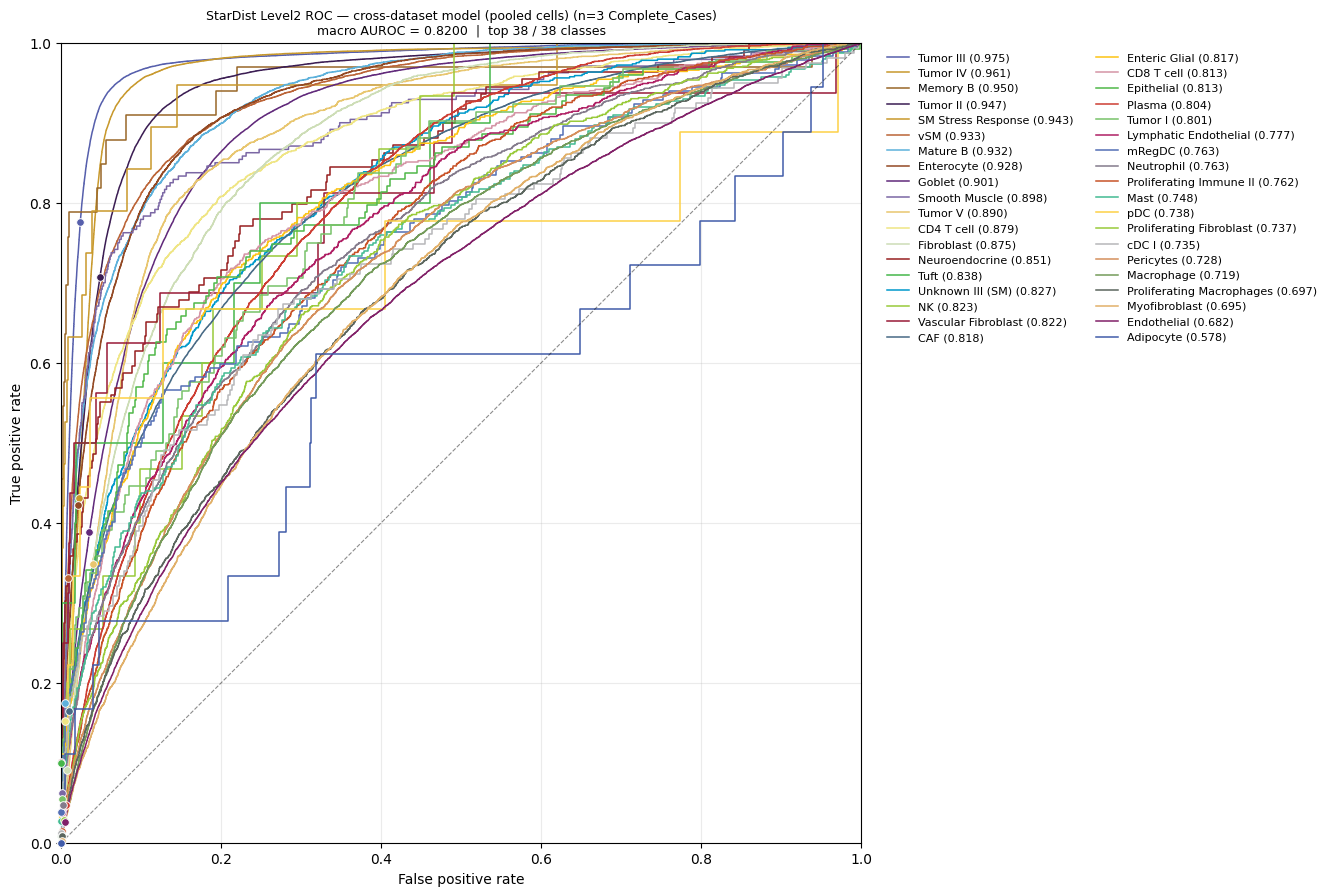

Pooled macro AUROC (L2): 0.8200

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  P1CRC: 77,901 cells, 9 local classes
  P2CRC: 63,166 cells, 9 local classes
  P5CRC: 80,649 cells, 9 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/validation_external_stardist_matched_AUROC_level12_all_samples_concat.csv (221,716 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/validation_external_stardist_matched_AUROC_level12_all_samples_class_names.csv (9 classes)
Pooled: 221,716 cells from 3 samples; 9 global final_sublineage classes
  ROC colors: xenium_crc_intermediate (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/roc_stardist_l12_cross_dataset_all_Complete_Cases_pooled.pdf


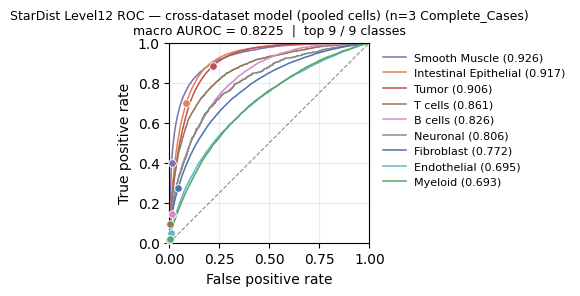

Pooled macro AUROC (L12): 0.8225

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  P1CRC: 77,901 cells, 4 local classes
  P2CRC: 63,166 cells, 4 local classes
  P5CRC: 80,649 cells, 4 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/validation_external_stardist_matched_AUROC_level1_all_samples_concat.csv (221,716 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/validation_external_stardist_matched_AUROC_level1_all_samples_class_names.csv (4 classes)
Pooled: 221,716 cells from 3 samples; 4 global final_lineage classes
  ROC colors: xenium_crc_coarse (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/roc_stardist_l1_cross_dataset_all_Complete_Cases_pooled.pdf


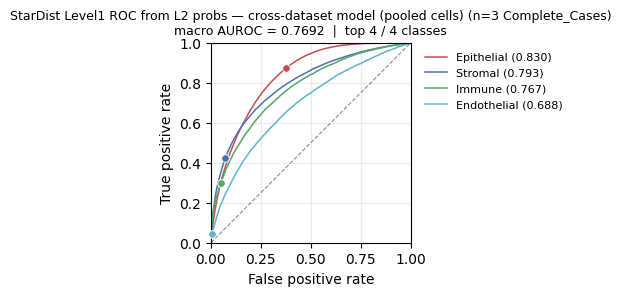

Pooled macro AUROC (L1): 0.7692
Wrote pooled ROC for: ['l2', 'l12', 'l1']


In [2]:
import importlib
import uni_label_cv_helpers as uni_nb

importlib.reload(uni_nb)
from uni_label_cv_helpers import (
    plot_pooled_stardist_tier_rocs,
    symlink_stardist_sample_dirs,
    build_stardist_sample_macro_auroc_table,
)

filtered_root = symlink_stardist_sample_dirs(
    STARDIST_RESULT_ROOT,
    SAMPLES,
    OUT_DIR / "_tmp_selected_stardist",
)

pooled_roc = plot_pooled_stardist_tier_rocs(
    filtered_root,
    OUT_DIR,
    TIERS,
    layout="pooled_stardist",
    pan_organ=PAN_ORGAN,
    figsize={"l12": (2.0, 2.0), "l1": (2.0, 2.0)},
)
print("Wrote pooled ROC for:", list(pooled_roc))


## Per-sample macro AUROC

One row per sample (`P1CRC`, `P2CRC`, …) and three-head columns `macro_auc_l2` / `macro_auc_l12` / `macro_auc_l1`.


,Sample,macro_auc_l2,macro_auc_l12,macro_auc_l1
0,P1CRC,0.771936,0.799730,0.734684
1,P2CRC,0.790805,0.827269,0.768536
2,P5CRC,0.786101,0.804636,0.779893


Wrote /home/lingyu/ssd2/Python/Hist2Pheno/data/Xemium/CRC/Results/result_all_spatial/pred_viz/stardist_macro_auroc_by_sample.csv


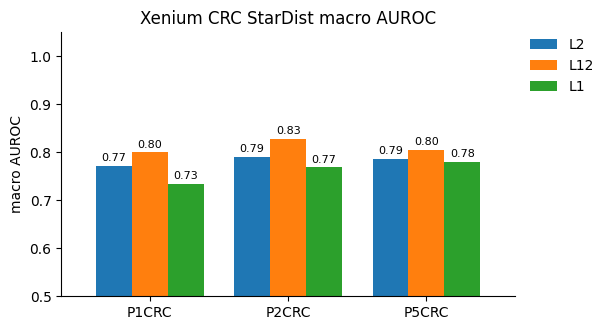

In [3]:
auroc_tbl = build_stardist_sample_macro_auroc_table(
    filtered_root,
    tiers=TIERS,
    layout="pooled_stardist",
)
out_csv = OUT_DIR / "stardist_macro_auroc_by_sample.csv"
if len(auroc_tbl):
    auroc_tbl.to_csv(out_csv, index=False)
    display(auroc_tbl)
    print("Wrote", out_csv)

    plot_df = auroc_tbl.set_index("Sample")
    cols = [c for c in plot_df.columns if c.startswith("macro_auc_")]
    rename = {c: c.replace("macro_auc_", "").upper() for c in cols}
    ax = plot_df[cols].rename(columns=rename).plot(
        kind="bar", figsize=(6.2, 3.4), rot=0, width=0.78
    )
    ax.set_ylabel("macro AUROC")
    ax.set_xlabel("")
    ax.set_ylim(0.5, 1.05)
    ax.set_title("Xenium CRC StarDist macro AUROC")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
    ax.legend(
        title=None,
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0,
    )
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(
        OUT_DIR / "stardist_macro_auroc_by_sample.pdf",
        bbox_inches="tight",
    )
    plt.show()
else:
    print(
        "No AUROC CSVs yet. Run the cross-dataset CLI / CRC_train_validate_cv_UNIlabel_all.ipynb first."
    )


## Notes

- CRC has no Response / diagnosis / treatment metadata, so this notebook does not run HCC clinical tests.
- Spatial prediction maps are written per sample under `Results/result_all_spatial/stardist/{P1CRC,P2CRC}/`.
- Palettes: `PAN_ORGAN="xenium_crc"` (Oliveira Flex L2 / coarse L1 colors).
- StarDist AUROC is vs **transferred RCTD** labels, not native Xenium GT.
